In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

os.listdir(path='drive/MyDrive')

['Home automation',
 'wire less electricity circuit.png',
 'LDR project.gdoc',
 'inverter',
 'Slider source code.gdoc',
 'Stack_game_playing_robot_using_Arduino_By_Glen_Tech.ino.gdoc',
 '2D servo CNC plotter.txt',
 'scaner.txt',
 '100 Days of Coding in Java.pdf',
 'hackathon.png',
 'ResumeLatest.gdoc',
 'Medlink Venture Survey .gform',
 'Newspaper Club Recruitment 2024-25.csv',
 'owner talking reel final.mp4',
 'Untitled spreadsheet.gsheet',
 'cover reel.mp4',
 'rec lis.gsheet',
 'sample.gsheet',
 'TechNov.jpeg',
 'Colab Notebooks',
 'SRS File git2know (1).docx',
 'news-a-thon round 2.gdoc',
 'Untitled document.gdoc',
 'OS lab -2 .gdoc',
 'OS Lab - 3.gdoc',
 'OS Lab - 4.gdoc',
 'ganesh.gdoc',
 'STS3007 Assignemnt questions.gdoc',
 'OS Lab - 7.gdoc',
 'OS Lab - 8.gdoc',
 'OS Lab - 9.gdoc',
 'OS Lab - 10.gdoc',
 'Palm.zip']

In [ ]:
import zipfile
zip_file_path = 'drive/My Drive/Palm.zip'
extract_path = ''
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
  zip_ref.extractall(extract_path)
os.listdir(path='.')

['.config', 'Palm', 'drive', 'sample_data']

In [ ]:
import os
import shutil

source_directory = "Palm"
anemic_destination_directory = "anemic"
non_anemic_destination_directory = "non-anemic"

os.makedirs(anemic_destination_directory, exist_ok=True)
os.makedirs(non_anemic_destination_directory, exist_ok=True)

anemic = 0
non_anemic = 0

for filename in os.listdir(source_directory):
    if filename.lower().endswith(".png"):
        source_path = os.path.join(source_directory, filename)
        if "anemic" in filename.lower() and "non-anemic" not in filename.lower():
            destination_path = os.path.join(anemic_destination_directory, filename)
            shutil.move(source_path, destination_path)
            anemic += 1
        else:
            destination_path = os.path.join(non_anemic_destination_directory, filename)
            shutil.move(source_path, destination_path)
            non_anemic += 1

print(f"Moved {anemic} anemic images to '{anemic_destination_directory}'")
print(f"Moved {non_anemic} non-anemic images to '{non_anemic_destination_directory}'")

Moved 2562 anemic images to 'anemic'
Moved 1698 non-anemic images to 'non-anemic'


In [ ]:
import os, cv2, csv
import numpy as np
from glob import glob
import pandas as pd

DATA_DIR = 'Palm'
ANEMIC_DIR = 'anemic'
NON_ANEMIC_DIR = 'non-anemic'
IMG_SIZE = (224, 224)

def extract_lab_means(img_path):
    img = cv2.imread(img_path)
    img = cv2.resize(img, IMG_SIZE)

    # --- Convert BGR → RGB ---
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # --- Apply RGB filtering ---
    mask_rgb = np.all((rgb >= 20) & (rgb <= 235), axis=-1)
    rgb_filtered = rgb[mask_rgb]

    if rgb_filtered.size == 0:
        return None  # skip if too dark or bright

    # --- Convert RGB → CIELAB ---
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    L, A, B = cv2.split(lab)

    # --- Apply L filtering ---
    mask_L = (L >= 59) & (L <= 100)
    L_filtered = L[mask_L]

    if L_filtered.size == 0:
        return None

    # --- Mean values ---
    L_mean = np.mean(L_filtered)
    A_mean = np.mean(A)
    B_mean = np.mean(B)
    return [L_mean, A_mean, B_mean]

rows = []
for label, folder in enumerate([NON_ANEMIC_DIR, ANEMIC_DIR]):  # 0=non, 1=anemic
    for img_path in glob(os.path.join(folder, '*.png')):
        vals = extract_lab_means(img_path)
        if vals is not None:
            rows.append([*vals, label])

# --- Save to CSV ---
csv_path = 'palm_lab_features.csv'
pd.DataFrame(rows, columns=['L_mean','A_mean','B_mean','label']).to_csv(csv_path, index=False)
print(f"✅ Saved LAB mean features to {csv_path}")
print(f"Total valid samples: {len(rows)}")

✅ Saved LAB mean features to palm_lab_features.csv
Total valid samples: 3360


Epoch 1/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.5808 - loss: 0.6702 - val_accuracy: 0.6208 - val_loss: 0.6515
Epoch 2/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6091 - loss: 0.6516 - val_accuracy: 0.6468 - val_loss: 0.6487
Epoch 3/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6299 - loss: 0.6486 - val_accuracy: 0.6468 - val_loss: 0.6530
Epoch 4/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6251 - loss: 0.6441 - val_accuracy: 0.6245 - val_loss: 0.6563
Epoch 5/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6317 - loss: 0.6343 - val_accuracy: 0.6468 - val_loss: 0.6493
Epoch 6/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6455 - loss: 0.6333 - val_accuracy: 0.6543 - val_loss: 0.6525
Epoch 7/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6225 - loss: 0.6347 - val_accuracy: 0.6506 - val_loss: 0.6435
Epoch 8/75
152/152 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6537 - loss: 0.6226 - val_accuracy: 0.


Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.77      0.80       269
           1       0.85      0.91      0.88       403

    accuracy                           0.85       672
   macro avg       0.85      0.84      0.84       672
weighted avg       0.85      0.85      0.85       672

Confusion Matrix:
 [[206  63]
 [ 38 365]]
✅ Model saved at: palm_lab_dense_model.h5


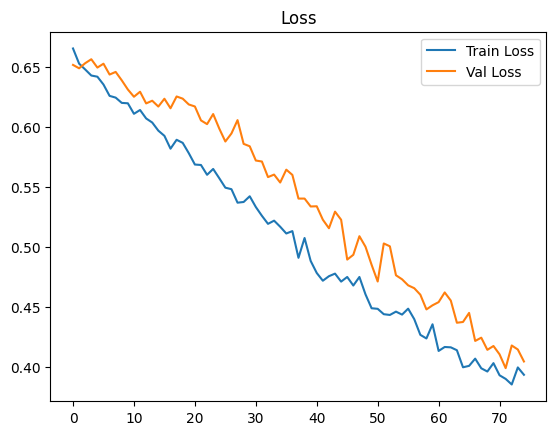

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Load CSV ---
data = pd.read_csv('palm_lab_features.csv')
X = data[['L_mean','A_mean','B_mean']].values
y = data['label'].values

# --- Normalize ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- Split ---
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify=y_train)

# --- Model (Dense version of AlexNet) ---
model = models.Sequential([
    layers.Input(shape=(3,)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=75,
    batch_size=16,
    verbose=1
)

# --- Evaluation ---
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"\nTest Accuracy: {test_acc*100:.2f}%")

y_pred = (model.predict(X_test) >= 0.5).astype(int)
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# --- Save Model ---
save_path = 'palm_lab_dense_model.h5'
model.save(save_path)
print(f"✅ Model saved at: {save_path}")

# --- Plot ---
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend(); plt.title('Loss')
plt.show()